# Assignment 4 — Multilingual Language Identification and Robustness Analysis

## 1. Reproducibility and libraries

Random seed: `42`. The split is stratified and performed **before** fitting TF-IDF vectorizers, so the vectorizers learn vocabulary only from the training split. The held-out test set is not used to tune the models.

In [1]:
import sys
import re
import random
import warnings
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_PATH = Path("data/language.csv")
KAZAKH_PATH = Path("data/kazakh_language.csv")  

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.2
pandas: 2.3.3
NumPy: 2.3.5


## 2. Load and inspect the supplied dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Put language.csv in the same folder as this notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
required_columns = {"Text", "language"}
missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}. Found: {df_raw.columns.tolist()}")

print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())
print("\nExamples per language:")
display(df_raw["language"].value_counts().rename_axis("language").reset_index(name="count"))

Shape: (22000, 2)
Columns: ['Text', 'language']


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Examples per language:


,language,count
0,Estonian,1000
1,Swedish,1000
2,Thai,1000
3,Tamil,1000
4,Dutch,1000
5,Japanese,1000
6,Turkish,1000
7,Latin,1000
8,Urdu,1000
9,Indonesian,1000


The supplied file has two columns: `Text` contains the language sample and `language` is its label. The dataset overview supplied with this file shows 22 language classes and 1,000 examples per class (22,000 rows total). The code below verifies these properties from the actual file.

## 3. Select 8 languages and optionally add Kazakh data

In [3]:
# Select English, Russian, and the closely related Spanish/Portuguese pair,
# plus French, Dutch, Swedish and Estonian from the supplied CSV.
# The CSV uses the spelling "Portugese" for Portuguese.
BASE_LANGUAGES = [
    "English", "Russian", "Spanish", "Portugese",
    "French", "Dutch", "Swedish", "Estonian"
]

df = df_raw[["Text", "language"]].copy()
df["Text"] = df["Text"].astype("string")
df["language"] = df["language"].astype("string").str.strip()

# Clean empty text/labels and exact duplicate rows.
df = df.dropna(subset=["Text", "language"])
df["Text"] = df["Text"].str.strip()
df = df[(df["Text"].str.len() > 0) & (df["language"].str.len() > 0)]
before_dedup = len(df)
df = df.drop_duplicates(subset=["Text", "language"]).reset_index(drop=True)
print("Duplicate rows removed:", before_dedup - len(df))

# Keep selected base languages.
df = df[df["language"].isin(BASE_LANGUAGES)].copy()

# Optional genuine Kazakh samples from a separate file.
if KAZAKH_PATH.exists():
    kaz = pd.read_csv(KAZAKH_PATH)
    if not {"Text", "language"}.issubset(kaz.columns):
        raise ValueError("kazakh.csv must contain columns named Text and language.")
    kaz = kaz[["Text", "language"]].copy()
    kaz["Text"] = kaz["Text"].astype("string").str.strip()
    kaz["language"] = "Kazakh"
    kaz = kaz.dropna(subset=["Text"])
    kaz = kaz[kaz["Text"].str.len() > 0]
    kaz = kaz.drop_duplicates(subset=["Text"])
    df = pd.concat([df, kaz], ignore_index=True)
    print(f"Loaded {len(kaz)} supplementary Kazakh examples from {KAZAKH_PATH}.")
else:
    print(
        "WARNING: kazakh.csv was not found. Baseline will run on 8 available languages, "
        "but it will NOT satisfy the assignment's Kazakh-language requirement. "
        "Add at least 500 genuine Kazakh examples in kazakh.csv and rerun."
    )

print("Selected dataset shape:", df.shape)
display(df["language"].value_counts().rename_axis("language").reset_index(name="count"))

# The assignment requires at least 500 samples for every language.
counts = df["language"].value_counts()
if (counts < 500).any():
    print("WARNING: Some selected languages have fewer than 500 examples:", counts[counts < 500].to_dict())

Duplicate rows removed: 141
Loaded 953 supplementary Kazakh examples from data\kazakh_language.csv.
Selected dataset shape: (8921, 2)


,language,count
0,English,1000
1,Estonian,999
2,Russian,999
3,Portugese,997
4,Spanish,996
5,Dutch,995
6,Swedish,992
7,French,990
8,Kazakh,953


### Dataset note
The supplied CSV does not contain Kazakh, so a supplementary file is necessary to satisfy the assignment fully. Use a documented source and preserve the original texts. The optional file should have two columns: `Text` and `language`; every row should contain a genuine Kazakh example. Do not label Russian or other-language text as Kazakh.

## 4. Two preprocessing strategies

In [4]:
def preprocess_intensive(text):
    # Approach A: lowercase, remove digits, punctuation and symbols,
    # while preserving Unicode letters from all languages.
    text = str(text).lower()
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    text = re.sub(r"_+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess_minimal(text):
    # Approach B: preserve letters, punctuation, digits and language-specific characters.
    # Only normalize whitespace and remove formatting artifacts.
    text = str(text).replace("\u200b", " ").replace("\ufeff", " ")
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text_intensive"] = df["Text"].map(preprocess_intensive)
df["text_minimal"] = df["Text"].map(preprocess_minimal)

display(df[["Text", "text_intensive", "text_minimal", "language"]].head(3))

,Text,text_intensive,text_minimal,language
0,klement gottwaldi surnukeha palsameeriti ning ...,klement gottwaldi surnukeha palsameeriti ning ...,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,sebes joseph pereira thomas på eng the jesuits...,sebes joseph pereira thomas på eng the jesuits...,Swedish
2,de spons behoort tot het geslacht haliclona en...,de spons behoort tot het geslacht haliclona en...,de spons behoort tot het geslacht haliclona en...,Dutch


**Rationale.** Intensive preprocessing reduces superficial variation but removes punctuation and digits that may carry information. Minimal preprocessing preserves more original information. Both approaches preserve Unicode letters, including Kazakh-specific letters such as ә, ғ, қ, ң, ө, ұ, ү, һ and і. For this dataset, many original texts are already lowercased and punctuation-light, so the measured difference may be modest.

## 5. Train/test split

In [5]:
# Split once, stratified by label. Feature vectorizers are fitted only on training text.
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=SEED,
    stratify=df["language"]
)

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("\nTrain distribution:")
display(train_df["language"].value_counts().sort_index())
print("\nTest distribution:")
display(test_df["language"].value_counts().sort_index())

Training rows: 7136
Test rows: 1785

Train distribution:


language
Dutch        796
English      800
Estonian     799
French       792
Kazakh       762
Portugese    797
Russian      799
Spanish      797
Swedish      794
Name: count, dtype: int64


Test distribution:


language
Dutch        199
English      200
Estonian     200
French       198
Kazakh       191
Portugese    200
Russian      200
Spanish      199
Swedish      198
Name: count, dtype: int64

## 6. Model configurations and feature representations

In [6]:
# Word-level TF-IDF: useful for frequent words and vocabulary.
# Character TF-IDF (1–3 grams): captures spelling and script patterns, often useful for short texts.
VECTORIZERS = {
    "word_tfidf": TfidfVectorizer(
        analyzer="word", ngram_range=(1, 2), min_df=2,
        max_features=150_000, sublinear_tf=True
    ),
    "char_tfidf": TfidfVectorizer(
        analyzer="char", ngram_range=(1, 3), min_df=2,
        max_features=250_000, sublinear_tf=True
    )
}

CLASSIFIERS = {
    "MultinomialNB": MultinomialNB(alpha=0.1),
    "LogisticRegression": LogisticRegression(
        max_iter=1000, C=4.0, random_state=SEED
    )
}

## 7. Train and evaluate all four configurations for both preprocessing strategies

In [7]:
results = []
trained_models = {}
predictions = {}

for prep_name, train_col, test_col in [
    ("intensive", "text_intensive", "text_intensive"),
    ("minimal", "text_minimal", "text_minimal")
]:
    X_train_text = train_df[train_col].fillna("").astype(str)
    X_test_text = test_df[test_col].fillna("").astype(str)
    y_train = train_df["language"].astype(str)
    y_test = test_df["language"].astype(str)

    for vectorizer_name, vectorizer_template in VECTORIZERS.items():
        # Fresh vectorizer per experiment; fit on train only.
        vectorizer = TfidfVectorizer(
            analyzer=vectorizer_template.analyzer,
            ngram_range=vectorizer_template.ngram_range,
            min_df=vectorizer_template.min_df,
            max_features=vectorizer_template.max_features,
            sublinear_tf=vectorizer_template.sublinear_tf
        )
        X_train = vectorizer.fit_transform(X_train_text)
        X_test = vectorizer.transform(X_test_text)

        for model_name, classifier_template in CLASSIFIERS.items():
            if model_name == "MultinomialNB":
                model = MultinomialNB(alpha=classifier_template.alpha)
            else:
                model = LogisticRegression(
                    max_iter=classifier_template.max_iter,
                    C=classifier_template.C,
                    random_state=SEED
                )

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            key = (prep_name, vectorizer_name, model_name)

            trained_models[key] = (vectorizer, model)
            predictions[key] = y_pred
            results.append({
                "preprocessing": prep_name,
                "features": vectorizer_name,
                "model": model_name,
                "accuracy": accuracy_score(y_test, y_pred),
                "macro_f1": f1_score(y_test, y_pred, average="macro"),
                "n_features": X_train.shape[1]
            })

results_df = pd.DataFrame(results).sort_values(
    ["macro_f1", "accuracy"], ascending=False
).reset_index(drop=True)
display(results_df)

,preprocessing,features,model,accuracy,macro_f1,n_features
0,minimal,char_tfidf,LogisticRegression,0.991597,0.991685,25170
1,intensive,char_tfidf,LogisticRegression,0.991036,0.991116,21921
2,intensive,word_tfidf,LogisticRegression,0.987675,0.987814,55735
3,minimal,word_tfidf,LogisticRegression,0.987675,0.987814,55735
4,intensive,word_tfidf,MultinomialNB,0.987675,0.987812,55735
5,minimal,word_tfidf,MultinomialNB,0.987675,0.987812,55735
6,minimal,char_tfidf,MultinomialNB,0.984314,0.984524,25170
7,intensive,char_tfidf,MultinomialNB,0.983754,0.983957,21921


## 8. Visualize comparison

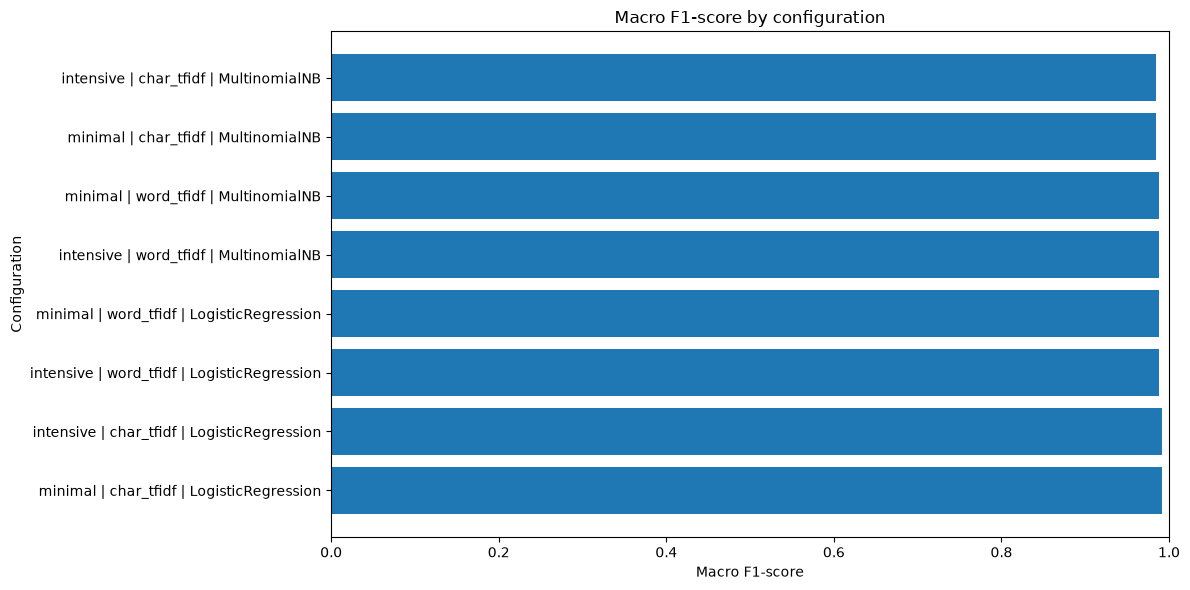

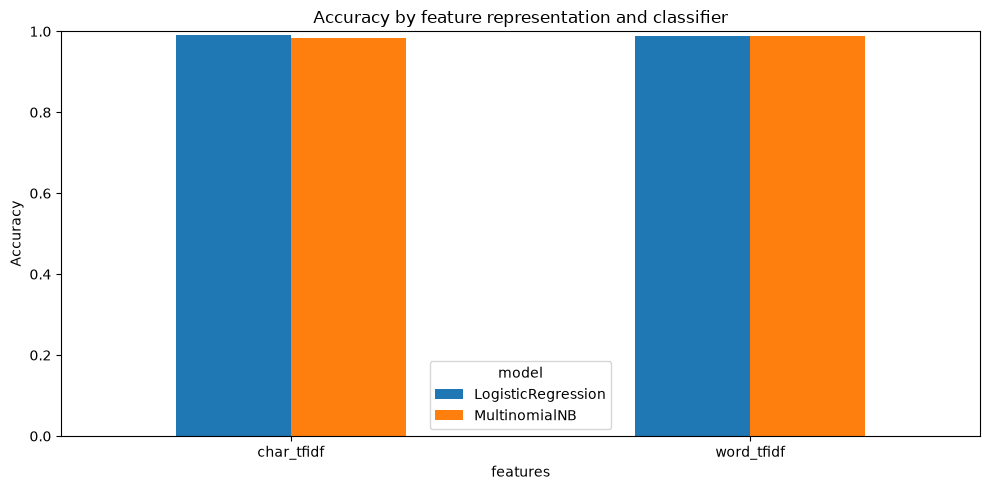

In [8]:
plot_df = results_df.copy()
plot_df["configuration"] = (
    plot_df["preprocessing"] + " | " + plot_df["features"] + " | " + plot_df["model"]
)
plt.figure(figsize=(12, 6))
plt.barh(plot_df["configuration"], plot_df["macro_f1"])
plt.title("Macro F1-score by configuration")
plt.xlabel("Macro F1-score")
plt.ylabel("Configuration")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

pivot_accuracy = results_df.pivot_table(index="features", columns="model", values="accuracy")
pivot_accuracy.plot(kind="bar", figsize=(10, 5))
plt.title("Accuracy by feature representation and classifier")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Best model: classification report and confusion matrix

Best configuration: ('minimal', 'char_tfidf', 'LogisticRegression')
Accuracy: 0.9916
Macro F1: 0.9917

Classification report:
              precision    recall  f1-score   support

       Dutch       0.99      0.99      0.99       199
     English       0.96      0.99      0.98       200
    Estonian       0.99      0.97      0.98       200
      French       1.00      0.99      0.99       198
      Kazakh       1.00      1.00      1.00       191
   Portugese       0.99      0.98      0.98       200
     Russian       0.99      0.99      0.99       200
     Spanish       1.00      0.99      1.00       199
     Swedish       1.00      1.00      1.00       198

    accuracy                           0.99      1785
   macro avg       0.99      0.99      0.99      1785
weighted avg       0.99      0.99      0.99      1785



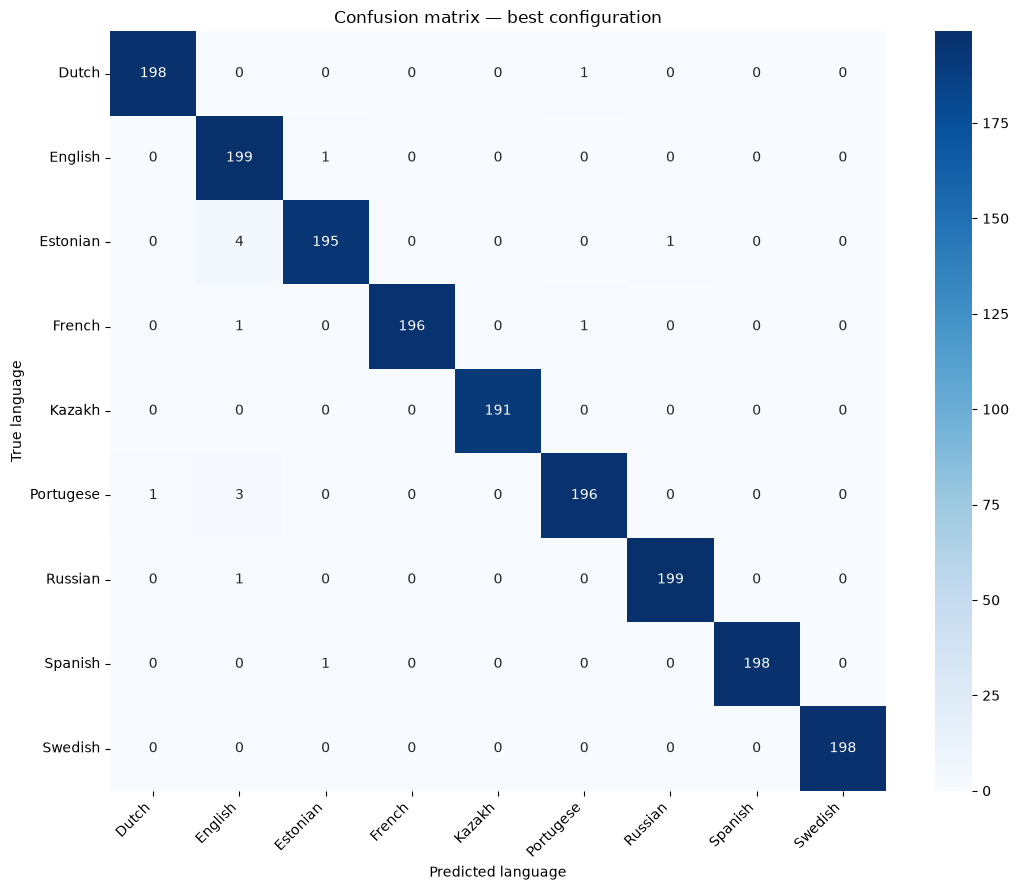

In [9]:
best_row = results_df.iloc[0]
best_key = (
    best_row["preprocessing"],
    best_row["features"],
    best_row["model"]
)
best_pred = predictions[best_key]
y_test = test_df["language"].astype(str)
labels = sorted(y_test.unique())

print("Best configuration:", best_key)
print(f"Accuracy: {accuracy_score(y_test, best_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, best_pred, average='macro'):.4f}")
print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

cm = confusion_matrix(y_test, best_pred, labels=labels)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Confusion matrix — best configuration")
ax.set_xlabel("Predicted language")
ax.set_ylabel("True language")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Robustness experiment A — text length

,length_group,samples,accuracy
0,1–3 words,0,NaN
1,4–10 words,1,1.000000
2,More than 10 words,1784,0.991592


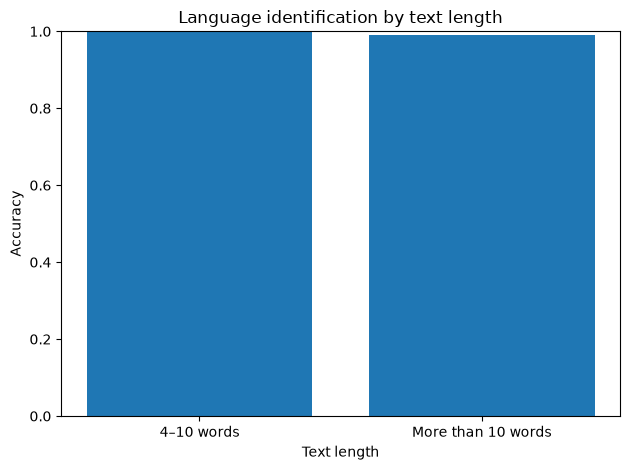

In [10]:
def word_count(text):
    return len(str(text).split())

robust_test = test_df[["Text", "language", "text_minimal"]].copy()
robust_test["word_count"] = robust_test["Text"].map(word_count)
robust_test["length_group"] = pd.cut(
    robust_test["word_count"],
    bins=[-1, 3, 10, np.inf],
    labels=["1–3 words", "4–10 words", "More than 10 words"]
)

# Use the best model's vectorizer and classifier on minimally processed test data
# if the best model used intensive preprocessing, transform accordingly.
best_prep, best_features, best_model_name = best_key
vectorizer, model = trained_models[best_key]
test_column = "text_intensive" if best_prep == "intensive" else "text_minimal"
X_length = vectorizer.transform(test_df[test_column].fillna("").astype(str))
length_predictions = model.predict(X_length)
robust_test["prediction"] = length_predictions
robust_test["correct"] = robust_test["prediction"] == robust_test["language"]

length_results = robust_test.groupby("length_group", observed=False).agg(
    samples=("correct", "size"),
    accuracy=("correct", "mean")
).reset_index()
length_results = length_results.dropna(subset=["length_group"])
display(length_results)

plt.bar(length_results["length_group"].astype(str), length_results["accuracy"].astype(float))
plt.title("Language identification by text length")
plt.xlabel("Text length")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 11. Robustness experiment B — controlled spelling noise

,condition,accuracy,macro_f1
0,Clean test set,0.991597,0.991685
1,Noisy test set,0.992157,0.992235


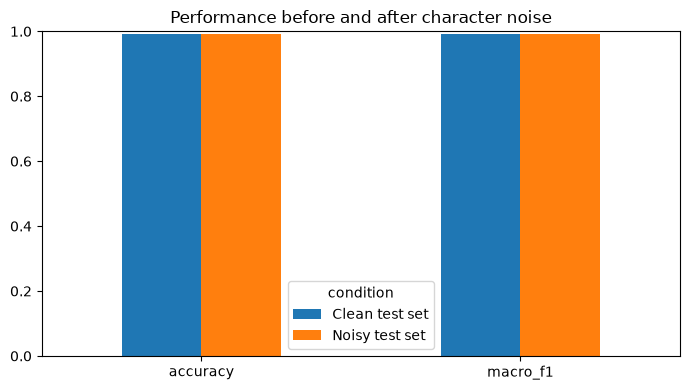

In [11]:
def add_character_noise(text, rng, rate=0.03):
    # For each eligible character, randomly delete, duplicate, or replace it.
    # This is a controlled perturbation for robustness testing, not a linguistic correction.
    chars = list(str(text))
    if len(chars) < 4:
        return str(text)
    alphabet = "abcdefghijklmnopqrstuvwxyz"
    out = []
    for ch in chars:
        if ch.isalpha() and rng.random() < rate:
            operation = rng.choice(["delete", "duplicate", "replace"])
            if operation == "delete":
                continue
            elif operation == "duplicate":
                out.extend([ch, ch])
            else:
                out.append(rng.choice(list(alphabet)))
        else:
            out.append(ch)
    return "".join(out)

rng = np.random.default_rng(SEED)
clean_texts = test_df[test_column].fillna("").astype(str).tolist()
noisy_texts = [add_character_noise(t, rng, rate=0.03) for t in clean_texts]

X_clean = vectorizer.transform(clean_texts)
X_noisy = vectorizer.transform(noisy_texts)
pred_clean = model.predict(X_clean)
pred_noisy = model.predict(X_noisy)
y_test = test_df["language"].astype(str).to_numpy()

noise_results = pd.DataFrame({
    "condition": ["Clean test set", "Noisy test set"],
    "accuracy": [
        accuracy_score(y_test, pred_clean),
        accuracy_score(y_test, pred_noisy)
    ],
    "macro_f1": [
        f1_score(y_test, pred_clean, average="macro"),
        f1_score(y_test, pred_noisy, average="macro")
    ]
})
display(noise_results)

noise_plot = noise_results.melt(id_vars="condition", var_name="metric", value_name="score")
noise_pivot = noise_results.set_index("condition")[ ["accuracy", "macro_f1"] ].T
noise_pivot.plot(kind="bar", figsize=(7, 4))
plt.xticks(rotation=0)
plt.title("Performance before and after character noise")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 12. Robustness experiment C — Kazakh–Russian code-switching

The following examples are **qualitative probes**, not part of the standard held-out test set. A sentence mixing languages does not necessarily have one objectively correct language label, so these results must not be reported as ordinary classification accuracy. The examples are illustrative and should be reviewed for naturalness before the final report.

In [12]:
code_switch_examples = [
    "Бүгін я пойду в университет после занятий.",
    "Мен завтра буду работать над проектом.",
    "Сабақтан кейін мы встретимся в библиотеке.",
    "Менің сегодня очень много домашних заданий.",
    "Ертең я отправлю тебе файл.",
    "Қазір мы будем изучать новую тему.",
    "Мен уже закончил тапсырманы.",
    "Сен можешь объяснить эту формулу?",
    "Бүгін у нас будет важная лекция.",
    "Мен хочу улучшить свой қазақский язык.",
    "Осы вопрос нужно обсудить завтра.",
    "Мен сегодня дайындаламын к экзамену.",
    "Кітапты я оставил дома.",
    "Біз после пары пойдём домой.",
    "Мұғалім сказал, что тест будет сложным.",
    "Мен не понимаю это задание толық.",
    "Сен отправил мне лекцияның файлдарын?",
    "Бүгін я буду читать новую статью.",
    "Ол сказал, что встреча басталады в пять.",
    "Менің телефоным опять не работает.",
    "Қандай фильм ты вчера смотрел?",
    "Біз завтра будем обсуждать результаты.",
    "Мен уже сделал анализ данных.",
    "Осы жерде можно найти нужную информацию.",
    "Мен хочу проверить свои ответы сейчас.",
    "Сен можешь помочь с этим кодом?",
    "Бүгін ауа райы хороший екен.",
    "Мен отправлю отчёт после завершения работы.",
    "Ол сегодня не пришёл на сабақ.",
    "Біз бірге будем готовиться к экзамену."
]

code_switch_df = pd.DataFrame({"Text": code_switch_examples})
code_switch_df["processed"] = code_switch_df["Text"].map(
    preprocess_intensive if best_prep == "intensive" else preprocess_minimal
)
X_cs = vectorizer.transform(code_switch_df["processed"])
code_switch_df["predicted_language"] = model.predict(X_cs)

if hasattr(model, "predict_proba"):
    code_switch_df["confidence"] = model.predict_proba(X_cs).max(axis=1)
else:
    code_switch_df["confidence"] = np.nan

display(code_switch_df)

,Text,processed,predicted_language,confidence
0,Бүгін я пойду в университет после занятий.,Бүгін я пойду в университет после занятий.,Russian,0.881616
1,Мен завтра буду работать над проектом.,Мен завтра буду работать над проектом.,Russian,0.901956
2,Сабақтан кейін мы встретимся в библиотеке.,Сабақтан кейін мы встретимся в библиотеке.,Russian,0.716034
3,Менің сегодня очень много домашних заданий.,Менің сегодня очень много домашних заданий.,Russian,0.861768
4,Ертең я отправлю тебе файл.,Ертең я отправлю тебе файл.,Russian,0.693819
5,Қазір мы будем изучать новую тему.,Қазір мы будем изучать новую тему.,Russian,0.752604
6,Мен уже закончил тапсырманы.,Мен уже закончил тапсырманы.,Russian,0.682322
7,Сен можешь объяснить эту формулу?,Сен можешь объяснить эту формулу?,Russian,0.742633
8,Бүгін у нас будет важная лекция.,Бүгін у нас будет важная лекция.,Russian,0.673753
9,Мен хочу улучшить свой қазақский язык.,Мен хочу улучшить свой қазақский язык.,Russian,0.706167


### Interpretation of code-switching
The classifier assigns exactly one label even when a sentence contains both Kazakh and Russian. It may select the language with more recognizable character n-grams or words, and the confidence score may be misleading because the model was trained on single-language examples. A more suitable approach would allow mixed-language labels, identify language spans, or abstain when the evidence is ambiguous.

## 13. Error analysis — at least five incorrect predictions

In [13]:
error_df = test_df[["Text", "language"]].copy()
error_df["prediction"] = best_pred
error_df["correct"] = error_df["language"].astype(str) == error_df["prediction"].astype(str)
error_df["word_count"] = error_df["Text"].map(word_count)
errors = error_df[~error_df["correct"]].copy()

print("Number of errors:", len(errors))
if len(errors) > 0:
    errors["true_vs_predicted"] = errors["language"].astype(str) + " → " + errors["prediction"].astype(str)
    display(errors[["Text", "language", "prediction", "word_count"]].head(10))
else:
    print("No errors were found on this test set for the selected configuration.")

print("\nMost common confusion pairs:")
if len(errors) > 0:
    display(errors.groupby(["language", "prediction"]).size().sort_values(ascending=False).head(10).rename("count").reset_index())

Number of errors: 15


,Text,language,prediction,word_count
88,neural network algorithms for the analyzing of...,Estonian,English,26
93,marino anesa dizionario della musica italiana ...,Dutch,Portugese,35
516,harlan luxenberg susan p limber dan olweus ass...,Estonian,English,18
614,one of the things we have published on astrolo...,Portugese,English,108
658,"p k pandajev ""мракобесие для простаков или как...",Estonian,Russian,27
745,lilie ralph-johannes ludwig claudia zielke bea...,Portugese,Dutch,25
861,angela scheider auguste und carl von littrow d...,Spanish,Estonian,16
885,tim heath c murali mohan rao vc nand lal riar ...,English,Estonian,33
941,on the content and object of presentations a p...,Estonian,English,19
1045,gillison douglas australia in the war of – se...,Portugese,English,26



Most common confusion pairs:


,language,prediction,count
0,Estonian,English,4
1,Portugese,English,3
2,English,Estonian,1
3,Dutch,Portugese,1
4,French,English,1
5,Estonian,Russian,1
6,French,Portugese,1
7,Portugese,Dutch,1
8,Russian,English,1
9,Spanish,Estonian,1


## 15. Conclusions (complete after running the notebook)

In [18]:
best = results_df.iloc[0]
print("Best classical configuration:")
print(f"  Preprocessing: {best['preprocessing']}")
print(f"  Features: {best['features']}")
print(f"  Classifier: {best['model']}")
print(f"  Accuracy: {best['accuracy']:.4f}")
print(f"  Macro F1-score: {best['macro_f1']:.4f}")

print("\nObserved noise robustness:")
display(noise_results)


Best classical configuration:
  Preprocessing: minimal
  Features: char_tfidf
  Classifier: LogisticRegression
  Accuracy: 0.9916
  Macro F1-score: 0.9917

Observed noise robustness:


,condition,accuracy,macro_f1
0,Clean test set,0.991597,0.991685
1,Noisy test set,0.992157,0.992235



Remember to base your final written conclusions on the actual tables and plots above.


## References and reproducibility

- Supplied dataset: `language.csv`, columns `Text` and `language` (22,000 rows, 22 labels as inspected).
- Optional Kazakh supplement: document the exact source and download date in your report.
- Random seed: `42`.
- Split: stratified 80% training / 20% test.
- Features: word TF-IDF (1–2 word n-grams) and character TF-IDF (1–3 character n-grams).
- Models: Multinomial Naive Bayes (`alpha=0.1`) and Logistic Regression (`C=4.0`, `max_iter=1000`).
- Metrics: Accuracy, Macro F1-score and confusion matrix.
- No vectorizer is fitted on the test data.